In [1]:
import torch

print("PyTorch Version:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch Version: 2.14.1+cu130
GPU Available: True
GPU Name: Tesla T4


In [3]:
!pip install importlib_resources


In [4]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "oxford_iiit_pet",
    with_info=True,
    as_supervised=False
)

print("Dataset downloaded successfully!")
print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.XH4CDM_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.XH4CDM_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Dataset downloaded successfully!
tfds.core.DatasetInfo(
    name='oxford_iiit_pet',
    full_name='oxford_iiit_pet/4.0.0',
    description="""
    The Oxford-IIIT pet dataset is a 37 category pet image dataset with roughly 200
    images for each class. The images have large variations in scale, pose and
    lighting. All images have an associated ground truth annotation of breed and
    species. Additionally, head bounding boxes are provided for the training split,
    allowing using this dataset for simple object detection tasks. In the test
    split, the bounding boxes are empty.
    """,
    homepage='http://www.robots.ox.ac.uk/~vgg/data/pets/',
    data_dir='/root/tensorflow_datasets/oxford_iiit_pet/4.0.0',
    file_format=tfrecord,
    download_size=773.52 MiB,
    dataset_size=773.68 MiB,
    features=FeaturesDict({
        'file_name': Text

In [5]:
# Check dataset splits
print("Available Splits:", info.splits.keys())

for split in info.splits:
    print(split, "Images:", info.splits[split].num_examples)

# Check one sample
sample = next(iter(dataset["train"]))

image = sample["image"].numpy()
mask = sample["segmentation_mask"].numpy()

print("\nImage Shape:", image.shape)
print("Image Data Type:", image.dtype)

print("Mask Shape:", mask.shape)
print("Mask Data Type:", mask.dtype)

print("Mask Unique Values:", set(mask.flatten().tolist()))

Available Splits: dict_keys(['train', 'test'])
train Images: 3680
test Images: 3669

Image Shape: (500, 500, 3)
Image Data Type: uint8
Mask Shape: (500, 500, 1)
Mask Data Type: uint8
Mask Unique Values: {1, 2, 3}


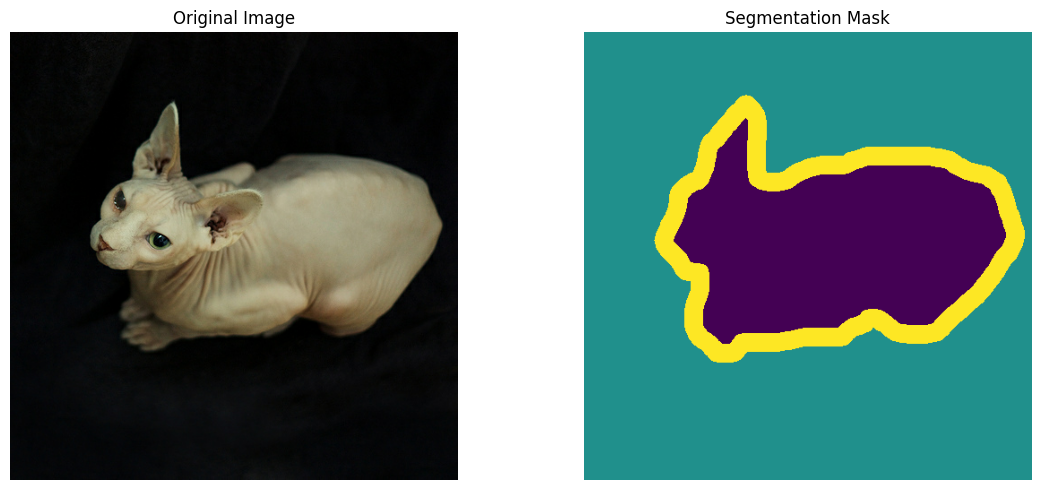

Unique Mask Values: [1 2 3]


In [6]:
import matplotlib.pyplot as plt
import numpy as np

sample = next(iter(dataset["train"]))

image = sample["image"].numpy()
mask = sample["segmentation_mask"].numpy().squeeze()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="viridis", vmin=1, vmax=3)
plt.title("Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Unique Mask Values:", np.unique(mask))

In [7]:
import numpy as np

sample = next(iter(dataset["train"]))

mask = sample["segmentation_mask"].numpy().squeeze()

total_pixels = mask.size

for class_id, class_name in [
    (1, "Pet / Foreground"),
    (2, "Background"),
    (3, "Boundary / Ignore")
]:
    count = np.sum(mask == class_id)
    percentage = (count / total_pixels) * 100

    print(f"{class_name}:")
    print("Pixel Count:", count)
    print("Percentage:", round(percentage, 2), "%")
    print("----------------------")

Pet / Foreground:
Pixel Count: 55672
Percentage: 22.27 %
----------------------
Background:
Pixel Count: 169695
Percentage: 67.88 %
----------------------
Boundary / Ignore:
Pixel Count: 24633
Percentage: 9.85 %
----------------------


In [8]:
# Reproducible train-validation split

SEED = 42

train_data = dataset["train"]

train_data = train_data.shuffle(
    buffer_size=3680,
    seed=SEED,
    reshuffle_each_iteration=False
)

val_dataset = train_data.take(736)
train_dataset = train_data.skip(736)

test_dataset = dataset["test"]

print("Training Images:", train_dataset.cardinality().numpy())
print("Validation Images:", val_dataset.cardinality().numpy())
print("Testing Images:", test_dataset.cardinality().numpy())

print("Random Seed:", SEED)

Training Images: 2944
Validation Images: 736
Testing Images: 3669
Random Seed: 42


In [10]:
import tensorflow as tf

IMG_SIZE = 256
IGNORE_LABEL = 255

def preprocess_data(sample):

    # Load image and mask
    image = sample["image"]
    mask = sample["segmentation_mask"]

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    # Normalize image
    image = image / 255.0

    # Resize mask without changing label IDs
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    mask = tf.cast(mask, tf.uint8)

    # Convert original labels:
    # 1 = Foreground
    # 2 = Background
    # 3 = Ignore

    mask = tf.where(
        mask == 1,
        1,
        tf.where(mask == 2, 0, IGNORE_LABEL)
    )

    return image, mask

In [11]:
sample = next(iter(dataset["train"]))

processed_image, processed_mask = preprocess_data(sample)

print("Processed Image Shape:", processed_image.shape)
print("Processed Mask Shape:", processed_mask.shape)

print("Image Range:",
      float(tf.reduce_min(processed_image)),
      "to",
      float(tf.reduce_max(processed_image)))

print("Mask Classes:",
      tf.unique(tf.reshape(processed_mask, [-1]))[0].numpy())

Processed Image Shape: (256, 256, 3)
Processed Mask Shape: (256, 256, 1)
Image Range: 0.0 to 0.7984046936035156
Mask Classes: [  0 255   1]


In [12]:
import tensorflow as tf

IMG_SIZE = 256
IGNORE_LABEL = 255

def preprocess_data(sample):

    image = sample["image"]
    mask = sample["segmentation_mask"]

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    # Normalize image
    image = image / 255.0

    # Resize mask
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    mask = tf.cast(mask, tf.uint8)

    # Convert mask labels
    mask = tf.where(
        mask == 1,
        1,
        tf.where(mask == 2, 0, IGNORE_LABEL)
    )

    return image, mask

In [13]:
sample = next(iter(dataset["train"]))

processed_image, processed_mask = preprocess_data(sample)

print("Image Shape:", processed_image.shape)
print("Mask Shape:", processed_mask.shape)

print("Image Range:",
      float(tf.reduce_min(processed_image)),
      "to",
      float(tf.reduce_max(processed_image)))

print("Mask Classes:",
      tf.unique(tf.reshape(processed_mask, [-1]))[0].numpy())

Image Shape: (256, 256, 3)
Mask Shape: (256, 256, 1)
Image Range: 0.0 to 0.7984046936035156
Mask Classes: [  0 255   1]


In [14]:
import tensorflow as tf

BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(data, training=False):

    data = data.map(
        preprocess_data,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        data = data.shuffle(
            buffer_size=1000,
            seed=42
        )

    data = data.batch(BATCH_SIZE)

    data = data.prefetch(AUTOTUNE)

    return data


# Prepare datasets
train_ds = prepare_dataset(train_dataset, training=True)
val_ds = prepare_dataset(val_dataset)
test_ds = prepare_dataset(test_dataset)

print("Data pipeline created successfully!")

Data pipeline created successfully!


In [15]:
images, masks = next(iter(train_ds))

print("Image Batch Shape:", images.shape)
print("Mask Batch Shape:", masks.shape)

print("Image Data Type:", images.dtype)
print("Mask Data Type:", masks.dtype)

print("Batch Size:", BATCH_SIZE)

Image Batch Shape: (16, 256, 256, 3)
Mask Batch Shape: (16, 256, 256, 1)
Image Data Type: <dtype: 'float32'>
Mask Data Type: <dtype: 'int32'>
Batch Size: 16


In [16]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(inputs, filters):

    x = layers.Conv2D(
        filters, 3, padding="same",
        activation="relu"
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(
        filters, 3, padding="same",
        activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)

    return x


def build_unet():

    inputs = layers.Input(shape=(256, 256, 3))

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    b = conv_block(p4, 256)

    # Decoder
    u4 = layers.UpSampling2D()(b)
    u4 = layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, 128)

    u3 = layers.UpSampling2D()(d4)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 64)

    u2 = layers.UpSampling2D()(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 32)

    u1 = layers.UpSampling2D()(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 16)

    # Output layer: 2 classes
    outputs = layers.Conv2D(
        2, 1, activation=None
    )(d1)

    model = Model(inputs, outputs, name="Baseline_UNet")

    return model


baseline_model = build_unet()

baseline_model.summary()

Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[

 Total params: 1,968,530 (7.51 MB)

 Trainable params: 1,965,586 (7.50 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [17]:
import tensorflow as tf

IGNORE_LABEL = 255

def masked_sparse_ce(y_true, y_pred):
    y_true = tf.squeeze(
        tf.cast(y_true, tf.int32), axis=-1
    )

    valid = tf.not_equal(y_true, IGNORE_LABEL)

    safe_labels = tf.where(
        valid, y_true, tf.zeros_like(y_true)
    )

    loss = tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=safe_labels,
        logits=y_pred
    )

    valid = tf.cast(valid, loss.dtype)

    return tf.math.divide_no_nan(
        tf.reduce_sum(loss * valid),
        tf.reduce_sum(valid)
    )


class MaskedMeanIoU(tf.keras.metrics.MeanIoU):

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.squeeze(
            tf.cast(y_true, tf.int32), axis=-1
        )

        y_pred = tf.argmax(
            y_pred, axis=-1, output_type=tf.int32
        )

        valid = tf.not_equal(y_true, IGNORE_LABEL)

        y_true = tf.boolean_mask(y_true, valid)
        y_pred = tf.boolean_mask(y_pred, valid)

        return super().update_state(
            y_true, y_pred, sample_weight
        )


print("Masked Loss and IoU Metric created successfully!")

Masked Loss and IoU Metric created successfully!


In [18]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=masked_sparse_ce,
    metrics=[
        MaskedMeanIoU(num_classes=2, name="mean_iou")
    ]
)

print("Baseline U-Net compiled successfully!")

Baseline U-Net compiled successfully!


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(inputs, filters):

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)

    x = layers.BatchNormalization()(x)

    return x


def build_unet():

    inputs = layers.Input(shape=(256, 256, 3))

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    b = conv_block(p4, 256)

    # Decoder
    u4 = layers.UpSampling2D()(b)
    u4 = layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, 128)

    u3 = layers.UpSampling2D()(d4)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 64)

    u2 = layers.UpSampling2D()(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 32)

    u1 = layers.UpSampling2D()(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 16)

    outputs = layers.Conv2D(2, 1, activation=None)(d1)

    model = Model(
        inputs,
        outputs,
        name="Baseline_UNet"
    )

    return model


baseline_model = build_unet()
baseline_model.summary()

Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[

 Total params: 1,968,530 (7.51 MB)

 Trainable params: 1,965,586 (7.50 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [4]:
print("Dataset:", "train_ds" in globals())
print("Validation:", "val_ds" in globals())
print("Test:", "test_ds" in globals())
print("Model:", "baseline_model" in globals())
print("Preprocessing:", "preprocess_data" in globals())

Dataset: False
Validation: False
Test: False
Model: True
Preprocessing: False


In [5]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "oxford_iiit_pet",
    with_info=True,
    as_supervised=False
)

print("Dataset loaded successfully!")
print("Train:", info.splits["train"].num_examples)
print("Test:", info.splits["test"].num_examples)

Dataset loaded successfully!
Train: 3680
Test: 3669


In [6]:
import tensorflow as tf

# Reproducible split
SEED = 42

train_full = dataset["train"].shuffle(
    3680,
    seed=SEED,
    reshuffle_each_iteration=False
)

train_dataset = train_full.take(2944)
val_dataset = train_full.skip(2944)

test_dataset = dataset["test"]

print("Training samples:", train_dataset.cardinality().numpy())
print("Validation samples:", val_dataset.cardinality().numpy())
print("Testing samples:", test_dataset.cardinality().numpy())

Training samples: 2944
Validation samples: 736
Testing samples: 3669


In [7]:
import tensorflow as tf

IMG_SIZE = 256
IGNORE_LABEL = 255

def preprocess_data(sample):

    image = sample["image"]
    mask = sample["segmentation_mask"]

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    image = image / 255.0

    # Resize mask
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    mask = tf.cast(mask, tf.uint8)

    # Foreground = 1, Background = 0, Boundary = 255
    mask = tf.where(
        mask == 1,
        1,
        tf.where(mask == 2, 0, IGNORE_LABEL)
    )

    return image, mask


print("Preprocessing function created successfully!")

Preprocessing function created successfully!


In [8]:
import tensorflow as tf

BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(data, training=False):

    data = data.map(
        preprocess_data,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        data = data.shuffle(
            buffer_size=1000,
            seed=42
        )

    data = data.batch(BATCH_SIZE)
    data = data.prefetch(AUTOTUNE)

    return data


train_ds = prepare_dataset(
    train_dataset, training=True
)

val_ds = prepare_dataset(val_dataset)

test_ds = prepare_dataset(test_dataset)

print("All datasets prepared successfully!")

All datasets prepared successfully!


In [9]:
for images, masks in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Mask batch shape:", masks.shape)

Image batch shape: (16, 256, 256, 3)
Mask batch shape: (16, 256, 256, 1)


In [12]:
import tensorflow as tf

IGNORE_LABEL = 255

def masked_sparse_ce(y_true, y_pred):

    y_true = tf.squeeze(
        tf.cast(y_true, tf.int32), axis=-1
    )

    valid = tf.not_equal(y_true, IGNORE_LABEL)

    safe_labels = tf.where(
        valid, y_true, tf.zeros_like(y_true)
    )

    loss = tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=safe_labels,
        logits=y_pred
    )

    valid = tf.cast(valid, loss.dtype)

    return tf.math.divide_no_nan(
        tf.reduce_sum(loss * valid),
        tf.reduce_sum(valid)
    )


class MaskedMeanIoU(tf.keras.metrics.MeanIoU):

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.squeeze(
            tf.cast(y_true, tf.int32), axis=-1
        )

        y_pred = tf.argmax(
            y_pred, axis=-1, output_type=tf.int32
        )

        valid = tf.not_equal(y_true, IGNORE_LABEL)

        y_true = tf.boolean_mask(y_true, valid)
        y_pred = tf.boolean_mask(y_pred, valid)

        return super().update_state(
            y_true, y_pred, sample_weight
        )


print("Masked Loss and IoU Metric created successfully!")

Masked Loss and IoU Metric created successfully!


In [13]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=masked_sparse_ce,
    metrics=[
        MaskedMeanIoU(
            num_classes=2,
            name="mean_iou"
        )
    ]
)

print("Baseline U-Net compiled successfully!")

Baseline U-Net compiled successfully!


In [15]:
import os
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/Reproducible_Segmentation_Experiment"

os.makedirs(PROJECT_DIR, exist_ok=True)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(PROJECT_DIR, "best_baseline.weights.h5"),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(PROJECT_DIR, "training_log.csv"),
    append=True
)

print("Checkpoint and training log setup completed!")

Checkpoint and training log setup completed!


In [ ]:
EPOCHS = 20

history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint_callback,
        csv_logger
    ]
)

Epoch 1/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - loss: 0.5577 - mean_iou: 0.5603
Epoch 1: val_loss improved from None to 0.79166, saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5
184/184 ━━━━━━━━━━━━━━━━━━━━ 130s 308ms/step - loss: 0.4491 - mean_iou: 0.6345 - val_loss: 0.7917 - val_mean_iou: 0.3494
Epoch 2/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - loss: 0.3293 - mean_iou: 0.7346
Epoch 2: val_loss improved from 0.79166 to 0.56410, saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5
184/184 ━━━━━━━━━━━━━━━━━━━━ 51s 220ms/step - loss: 0.3040 - mean_iou: 0.7550 - val_loss: 0.5641 - val_mean_iou: 0.7011
Epoch 3/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 

In [4]:
!pip install -q tensorflow-datasets

import tensorflow_datasets as tfds
import tensorflow as tf

dataset, info = tfds.load(
    "oxford_iiit_pet",
    with_info=True,
    as_supervised=False
)

print("Dataset loaded successfully!")
print("Training:", info.splits["train"].num_examples)
print("Testing:", info.splits["test"].num_examples)

Dataset loaded successfully!
Training: 3680
Testing: 3669


In [5]:
SEED = 42

train_full = dataset["train"].shuffle(
    3680,
    seed=SEED,
    reshuffle_each_iteration=False
)

train_dataset = train_full.take(2944)
val_dataset = train_full.skip(2944)
test_dataset = dataset["test"]

print("Training:", train_dataset.cardinality().numpy())
print("Validation:", val_dataset.cardinality().numpy())
print("Testing:", test_dataset.cardinality().numpy())

Training: 2944
Validation: 736
Testing: 3669


In [6]:
import tensorflow as tf

IMG_SIZE = 256
IGNORE_LABEL = 255

def preprocess_data(sample):

    image = sample["image"]
    mask = sample["segmentation_mask"]

    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    image = image / 255.0

    mask = tf.image.resize(
        mask, [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    mask = tf.cast(mask, tf.uint8)

    mask = tf.where(
        mask == 1,
        1,
        tf.where(mask == 2, 0, IGNORE_LABEL)
    )

    return image, mask

print("Preprocessing function created successfully!")

Preprocessing function created successfully!


In [7]:
import tensorflow as tf

BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(data, training=False):

    data = data.map(
        preprocess_data,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        data = data.shuffle(
            buffer_size=1000,
            seed=42
        )

    data = data.batch(BATCH_SIZE)
    data = data.prefetch(AUTOTUNE)

    return data


train_ds = prepare_dataset(train_dataset, training=True)
val_ds = prepare_dataset(val_dataset)
test_ds = prepare_dataset(test_dataset)

print("Training pipeline ready!")
print("Batch size:", BATCH_SIZE)

Training pipeline ready!
Batch size: 8


In [8]:
for images, masks in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Mask shape:", masks.shape)

Image shape: (8, 256, 256, 3)
Mask shape: (8, 256, 256, 1)


In [9]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(inputs, filters):

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(inputs)
    x = layers.BatchNormalization()(x)

    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    x = layers.BatchNormalization()(x)

    return x


def build_unet():

    inputs = layers.Input(shape=(256, 256, 3))

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    # Bottleneck
    b = conv_block(p4, 256)

    # Decoder
    u4 = layers.UpSampling2D()(b)
    u4 = layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, 128)

    u3 = layers.UpSampling2D()(d4)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 64)

    u2 = layers.UpSampling2D()(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 32)

    u1 = layers.UpSampling2D()(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 16)

    outputs = layers.Conv2D(2, 1)(d1)

    return Model(inputs, outputs, name="Baseline_UNet")


baseline_model = build_unet()
baseline_model.summary()

Model: "Baseline_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │         64 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[

 Total params: 1,968,530 (7.51 MB)

 Trainable params: 1,965,586 (7.50 MB)

 Non-trainable params: 2,944 (11.50 KB)

In [10]:
import tensorflow as tf

IGNORE_LABEL = 255

def masked_sparse_ce(y_true, y_pred):

    y_true = tf.squeeze(
        tf.cast(y_true, tf.int32), axis=-1
    )

    valid = tf.not_equal(y_true, IGNORE_LABEL)

    safe_labels = tf.where(
        valid, y_true, tf.zeros_like(y_true)
    )

    loss = tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=safe_labels,
        logits=y_pred
    )

    valid = tf.cast(valid, loss.dtype)

    return tf.math.divide_no_nan(
        tf.reduce_sum(loss * valid),
        tf.reduce_sum(valid)
    )


class MaskedMeanIoU(tf.keras.metrics.MeanIoU):

    def update_state(self, y_true, y_pred, sample_weight=None):

        y_true = tf.squeeze(
            tf.cast(y_true, tf.int32), axis=-1
        )

        y_pred = tf.argmax(
            y_pred, axis=-1, output_type=tf.int32
        )

        valid = tf.not_equal(y_true, IGNORE_LABEL)

        y_true = tf.boolean_mask(y_true, valid)
        y_pred = tf.boolean_mask(y_pred, valid)

        return super().update_state(
            y_true, y_pred, sample_weight
        )


print("Loss and IoU Metric created successfully!")

Loss and IoU Metric created successfully!


In [11]:
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=masked_sparse_ce,
    metrics=[
        MaskedMeanIoU(
            num_classes=2,
            name="mean_iou"
        )
    ]
)

print("Baseline U-Net compiled successfully!")

Baseline U-Net compiled successfully!


In [13]:
import os
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/Reproducible_Segmentation_Experiment"

os.makedirs(PROJECT_DIR, exist_ok=True)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(
        PROJECT_DIR,
        "best_baseline.weights.h5"
    ),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

csv_logger = tf.keras.callbacks.CSVLogger(
    os.path.join(PROJECT_DIR, "training_log.csv"),
    append=True
)

print("Checkpoint setup successful!")

Checkpoint setup successful!


In [ ]:
EPOCHS = 20

history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        checkpoint_callback,
        csv_logger
    ]
)

Epoch 1/20
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 0.5231 - mean_iou: 0.5726
Epoch 1: val_loss improved from None to 0.95891, saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5
368/368 ━━━━━━━━━━━━━━━━━━━━ 136s 171ms/step - loss: 0.4293 - mean_iou: 0.6453 - val_loss: 0.9589 - val_mean_iou: 0.5901
Epoch 2/20
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - loss: 0.3143 - mean_iou: 0.7449
Epoch 2: val_loss improved from 0.95891 to 0.29798, saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_baseline.weights.h5
368/368 ━━━━━━━━━━━━━━━━━━━━ 53s 117ms/step - loss: 0.2971 - mean_iou: 0.7579 - val_loss: 0.2980 - val_mean_iou: 0.7476
Epoch 3/20
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s

In [2]:
import os
import tensorflow as tf

PROJECT_DIR = "/content/drive/MyDrive/Reproducible_Segmentation_Experiment"

print("GPU:", tf.config.list_physical_devices('GPU'))
print("Checkpoint exists:",
      os.path.exists(PROJECT_DIR + "/best_baseline.weights.h5"))
print("Project files:", os.listdir(PROJECT_DIR))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Checkpoint exists: True
Project files: ['best_baseline.weights.h5', 'training_log.csv']


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def conv_block(inputs, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    return x

def build_unet():
    inputs = layers.Input(shape=(256, 256, 3))
    c1 = conv_block(inputs, 16); p1 = layers.MaxPooling2D()(c1)
    c2 = conv_block(p1, 32); p2 = layers.MaxPooling2D()(c2)
    c3 = conv_block(p2, 64); p3 = layers.MaxPooling2D()(c3)
    c4 = conv_block(p3, 128); p4 = layers.MaxPooling2D()(c4)
    b = conv_block(p4, 256)

    u4 = layers.UpSampling2D()(b)
    u4 = layers.Concatenate()([u4, c4])
    d4 = conv_block(u4, 128)

    u3 = layers.UpSampling2D()(d4)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 64)

    u2 = layers.UpSampling2D()(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 32)

    u1 = layers.UpSampling2D()(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 16)

    outputs = layers.Conv2D(2, 1)(d1)
    return Model(inputs, outputs, name="Baseline_UNet")

baseline_model = build_unet()
baseline_model.load_weights(
    PROJECT_DIR + "/best_baseline.weights.h5"
)

print("Weights loaded successfully!")
print("Parameters:", baseline_model.count_params())

Weights loaded successfully!
Parameters: 1968530


In [7]:
image, mask = next(iter(test_dataset))

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask values:", tf.unique(tf.reshape(mask, [-1]))[0].numpy())

Image shape: (500, 403, 3)
Mask shape: ()
Mask dtype: <dtype: 'int64'>
Mask values: [19]


In [8]:
dataset, info = tfds.load(
    "oxford_iiit_pet:4.0.0",
    with_info=True,
    as_supervised=False
)

sample = next(iter(dataset["test"]))

print("Image:", sample["image"].shape)
print("Mask:", sample["segmentation_mask"].shape)
print("Mask values:",
      tf.unique(
          tf.reshape(sample["segmentation_mask"], [-1])
      )[0].numpy())

Image: (500, 403, 3)
Mask: (500, 403, 1)
Mask values: [2 3 1]


In [9]:
def preprocess_data(sample):
    image = sample["image"]
    mask = sample["segmentation_mask"]

    image = tf.image.resize(image, (256, 256))
    image = tf.cast(image, tf.float32) / 255.0

    mask = tf.image.resize(
        mask, (256, 256), method="nearest"
    )
    mask = tf.cast(mask, tf.uint8)

    # 1 = Foreground, 2 = Background, 3 = Ignore
    mask = tf.where(
        mask == 1, 1,
        tf.where(mask == 2, 0, 255)
    )

    return image, mask

test_ds = (
    dataset["test"]
    .map(preprocess_data, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(8)
    .prefetch(tf.data.AUTOTUNE)
)

print("Test batches:",
      tf.data.experimental.cardinality(test_ds).numpy())

Test batches: 459


In [11]:
IGNORE_LABEL = 255

def masked_sparse_ce(y_true, y_pred):
    y_true = tf.squeeze(tf.cast(y_true, tf.int32), axis=-1)
    valid = tf.not_equal(y_true, IGNORE_LABEL)
    safe_labels = tf.where(valid, y_true, 0)

    loss = tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=safe_labels, logits=y_pred
    )

    valid = tf.cast(valid, loss.dtype)
    return tf.math.divide_no_nan(
        tf.reduce_sum(loss * valid),
        tf.reduce_sum(valid)
    )


class MaskedMeanIoU(tf.keras.metrics.MeanIoU):
    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true = tf.squeeze(tf.cast(y_true, tf.int32), axis=-1)
        y_pred = tf.argmax(y_pred, axis=-1, output_type=tf.int32)

        valid = tf.not_equal(y_true, IGNORE_LABEL)
        y_true = tf.boolean_mask(y_true, valid)
        y_pred = tf.boolean_mask(y_pred, valid)

        return super().update_state(y_true, y_pred, sample_weight)


baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=masked_sparse_ce,
    metrics=[MaskedMeanIoU(num_classes=2, name="mean_iou")]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
results = baseline_model.evaluate(test_ds, verbose=1)

print("Baseline Test Loss:", results[0])
print("Baseline Test mIoU:", results[1])

459/459 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/step - loss: 0.3004 - mean_iou: 0.7469
Baseline Test Loss: 0.30039334297180176
Baseline Test mIoU: 0.7469296455383301


In [13]:
import numpy as np
import tensorflow as tf

conf_matrix = tf.zeros((2, 2), dtype=tf.int64)

for images, masks in test_ds:
    predictions = baseline_model(images, training=False)
    predictions = tf.argmax(
        predictions, axis=-1, output_type=tf.int32
    )

    masks = tf.squeeze(tf.cast(masks, tf.int32), axis=-1)

    valid = tf.not_equal(masks, 255)
    true_labels = tf.boolean_mask(masks, valid)
    pred_labels = tf.boolean_mask(predictions, valid)

    batch_matrix = tf.math.confusion_matrix(
        true_labels,
        pred_labels,
        num_classes=2,
        dtype=tf.int64
    )

    conf_matrix += batch_matrix

# IoU calculation
matrix = conf_matrix.numpy()
intersection = np.diag(matrix)
union = matrix.sum(axis=0) + matrix.sum(axis=1) - intersection
class_iou = intersection / np.maximum(union, 1)

print("Confusion Matrix:\n", matrix)
print("Background IoU:", round(class_iou[0], 4))
print("Foreground IoU:", round(class_iou[1], 4))
print("Mean IoU:", round(class_iou.mean(), 4))

Confusion Matrix:
 [[134342887   4444015]
 [ 21795148  50317816]]
Background IoU: 0.8366
Foreground IoU: 0.6573
Mean IoU: 0.7469


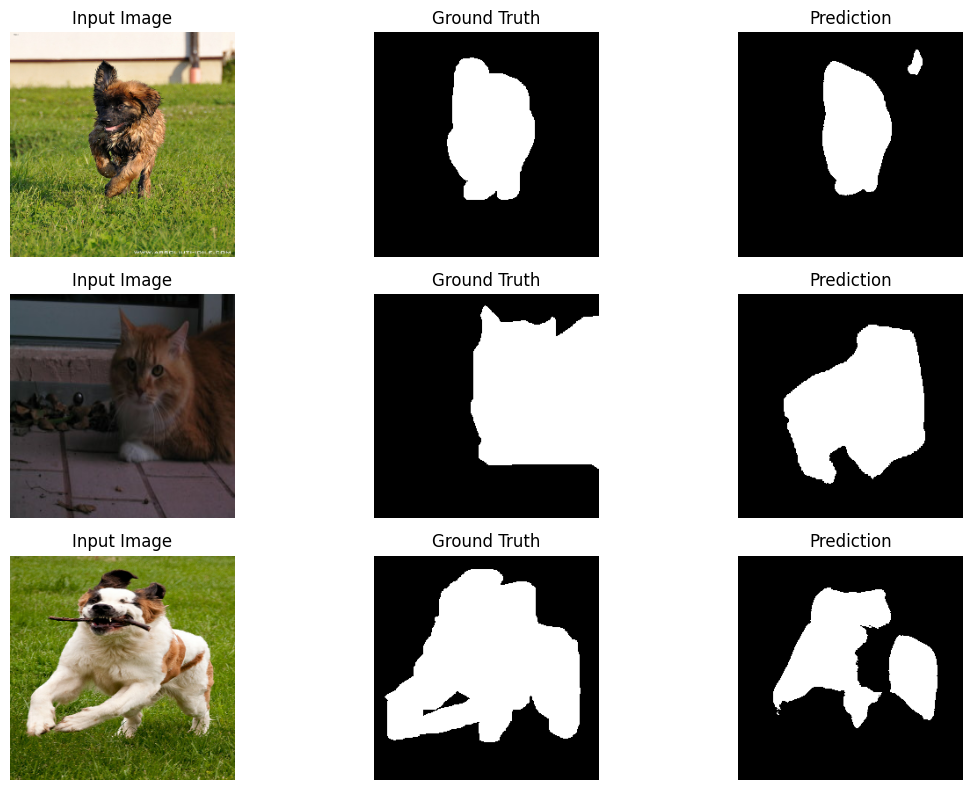

In [14]:
import matplotlib.pyplot as plt
import numpy as np

images, masks = next(iter(test_ds))
predictions = baseline_model(images, training=False)
predictions = tf.argmax(predictions, axis=-1).numpy()

plt.figure(figsize=(12, 8))

for i in range(3):
    plt.subplot(3, 3, i*3+1)
    plt.imshow(images[i])
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(3, 3, i*3+2)
    plt.imshow(masks[i, :, :, 0], cmap="gray", vmin=0, vmax=1)
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(3, 3, i*3+3)
    plt.imshow(predictions[i], cmap="gray", vmin=0, vmax=1)
    plt.title("Prediction")
    plt.axis("off")

plt.tight_layout()
plt.savefig(PROJECT_DIR + "/baseline_predictions.png", dpi=150)
plt.show()

In [16]:
def build_modified_unet():
    inputs = layers.Input(shape=(256, 256, 3))

    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 128)
    p4 = layers.MaxPooling2D()(c4)

    b = conv_block(p4, 256)

    # Decoder 4
    u4 = layers.UpSampling2D()(b)
    u4 = layers.Conv2D(128, 1, padding="same")(u4)
    u4 = layers.Add()([u4, c4])
    d4 = conv_block(u4, 128)

    # Decoder 3
    u3 = layers.UpSampling2D()(d4)
    u3 = layers.Conv2D(64, 1, padding="same")(u3)
    u3 = layers.Add()([u3, c3])
    d3 = conv_block(u3, 64)

    # Decoder 2
    u2 = layers.UpSampling2D()(d3)
    u2 = layers.Conv2D(32, 1, padding="same")(u2)
    u2 = layers.Add()([u2, c2])
    d2 = conv_block(u2, 32)

    # Decoder 1
    u1 = layers.UpSampling2D()(d2)
    u1 = layers.Conv2D(16, 1, padding="same")(u1)
    u1 = layers.Add()([u1, c1])
    d1 = conv_block(u1, 16)

    outputs = layers.Conv2D(2, 1)(d1)

    return Model(inputs, outputs, name="Modified_UNet_Add")


modified_model = build_modified_unet()

modified_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=masked_sparse_ce,
    metrics=[MaskedMeanIoU(num_classes=2, name="mean_iou")]
)

print("Modified model created successfully!")
print("Parameters:", modified_model.count_params())

Modified model created successfully!
Parameters: 1620610


In [17]:
import os
import pandas as pd

print("Baseline training history:")
print(pd.read_csv(PROJECT_DIR + "/training_log.csv").tail())

Baseline training history:
   epoch      loss  mean_iou  val_loss  val_mean_iou
2      2  0.252047  0.795381  2.237182      0.405915
3      0  0.429251  0.645323  0.958906      0.590119
4      1  0.297052  0.757915  0.297984      0.747608
5      2  0.251489  0.796653  0.769121      0.680530
6      3  0.227279  0.815825  0.621785      0.602405


In [18]:
import os

modified_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(PROJECT_DIR, "best_modified.weights.h5"),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

modified_csv = tf.keras.callbacks.CSVLogger(
    os.path.join(PROJECT_DIR, "modified_training_log.csv"),
    append=False
)

history_modified = modified_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=4,
    callbacks=[modified_checkpoint, modified_csv],
    verbose=1
)

Epoch 1/4
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.5654 - mean_iou: 0.5430
Epoch 1: val_loss improved from None to 1.16889, saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_modified.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_modified.weights.h5
368/368 ━━━━━━━━━━━━━━━━━━━━ 118s 134ms/step - loss: 0.4497 - mean_iou: 0.6263 - val_loss: 1.1689 - val_mean_iou: 0.4832
Epoch 2/4
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.3231 - mean_iou: 0.7406
Epoch 2: val_loss improved from 1.16889 to 0.32261, saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_modified.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Reproducible_Segmentation_Experiment/best_modified.weights.h5
368/368 ━━━━━━━━━━━━━━━━━━━━ 58s 135ms/step - loss: 0.3056 - mean_iou: 0.7530 - val_loss: 0.3226 - val_mean_iou: 0.7464
Epoch 3/4
368/368 ━━━━━━━━━━━━━━━━━━━━ 0s 78

In [19]:
# Best checkpoint load (Epoch 2)
modified_model.load_weights(
    PROJECT_DIR + "/best_modified.weights.h5"
)

# Test evaluation
modified_results = modified_model.evaluate(
    test_ds, verbose=1
)

print("\nMODIFIED MODEL RESULTS")
print("Test Loss:", modified_results[0])
print("Test mIoU:", modified_results[1])

459/459 ━━━━━━━━━━━━━━━━━━━━ 26s 57ms/step - loss: 0.3152 - mean_iou: 0.7552

MODIFIED MODEL RESULTS
Test Loss: 0.31517067551612854
Test mIoU: 0.7552226781845093


In [20]:
import time
import tensorflow as tf

sample_images, _ = next(iter(test_ds))
sample = sample_images[:1]

def measure_latency(model, name):
    # Warm-up
    for _ in range(10):
        _ = model(sample, training=False).numpy()

    # Measurement
    start = time.perf_counter()
    for _ in range(50):
        _ = model(sample, training=False).numpy()
    end = time.perf_counter()

    latency = ((end - start) / 50) * 1000
    print(f"{name}: {latency:.2f} ms/image")

print("Device:", tf.config.list_physical_devices("GPU"))
measure_latency(baseline_model, "Baseline U-Net")
measure_latency(modified_model, "Modified U-Net")

Device: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Baseline U-Net: 100.73 ms/image
Modified U-Net: 90.49 ms/image


In [5]:
models = list(globals().items())

for name, obj in models:
    if hasattr(obj, "summary") and hasattr(obj, "layers"):
        print("Variable:", name)
        print("Model:", obj.name)

In [7]:
%whos

Variable     Type        Data/Info
----------------------------------
Image        type        <class 'IPython.core.display.Image'>
display      function    <function display at 0x7900405ae980>
models       list        n=30
name         str         _i5
obj          str         models = list(globals().i<...>print("Model:", obj.name)
plot_model   function    <function plot_model at 0x78ffbfc72020>


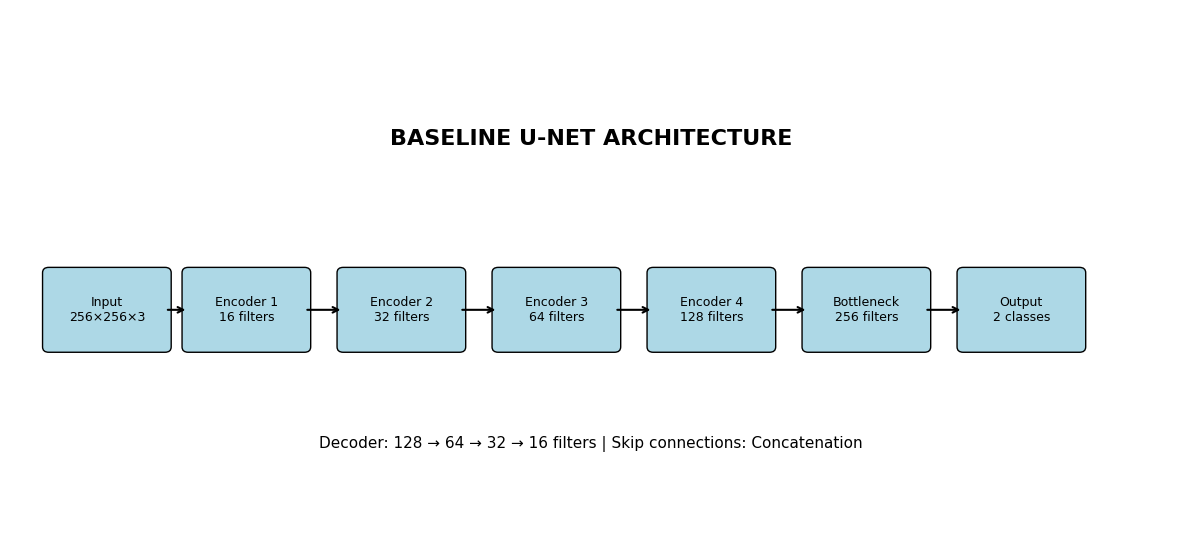

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 7))
ax.set_xlim(0, 15)
ax.set_ylim(0, 8)
ax.axis("off")

blocks = [
    (0.5, 3, "Input\n256×256×3"),
    (2.3, 3, "Encoder 1\n16 filters"),
    (4.3, 3, "Encoder 2\n32 filters"),
    (6.3, 3, "Encoder 3\n64 filters"),
    (8.3, 3, "Encoder 4\n128 filters"),
    (10.3, 3, "Bottleneck\n256 filters"),
    (12.3, 3, "Output\n2 classes")
]

for x, y, label in blocks:
    box = FancyBboxPatch((x, y), 1.5, 1.1,
                         boxstyle="round,pad=0.08",
                         edgecolor="black", facecolor="lightblue")
    ax.add_patch(box)
    ax.text(x + 0.75, y + 0.55, label,
            ha="center", va="center", fontsize=9)

for i in range(len(blocks)-1):
    x1 = blocks[i][0] + 1.5
    x2 = blocks[i+1][0]
    ax.annotate("", xy=(x2, 3.55), xytext=(x1, 3.55),
                arrowprops=dict(arrowstyle="->", lw=1.5))

ax.text(7.5, 6, "BASELINE U-NET ARCHITECTURE",
        ha="center", fontsize=16, weight="bold")
ax.text(7.5, 1.5,
        "Decoder: 128 → 64 → 32 → 16 filters | Skip connections: Concatenation",
        ha="center", fontsize=11)

plt.savefig("Baseline_UNet_Diagram.png", dpi=200, bbox_inches="tight")
plt.show()